In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
from datetime import datetime
import pickle
import dill
import random
from typing import Optional

sys.path.append(str(NB_DIR))

import torch

from botorch.optim import optimize_acqf
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.acquisition.monte_carlo import qExpectedImprovement
from botorch.acquisition.objective import ConstrainedMCObjective, LinearMCObjective
from botorch.models import ModelListGP, SingleTaskGP
from botorch import fit_gpytorch_mll
from gpytorch.mlls.sum_marginal_log_likelihood import SumMarginalLogLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood

from matal.utils import load_cache
from matal.configs import DATA_DIR
from matal.utils.datatype import to_torch
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matal.recipe import UniformCompositionGenerator, get_rand_comp
from matal.utils import auto_log, get_sid, obj_to_hash, merge_update, Bunch, cache_return, load_cache, save_cache
from matal.configs import BATCH_DIR, PROJ_CODE, MODEL_DIR, DATA_DIR
from matal.robot.ot2 import OT2ProcGeneratorV7

try:
    from sklearn.utils._testing import ignore_warnings
except ImportError:
    from sklearn.utils.testing import ignore_warnings

INFO:numexpr.utils:NumExpr defaulting to 8 threads.


## 0. Load SVM models

In [2]:
svm_models = load_cache('svm_models_v8')
display(svm_models)

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1.0])

from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
print(f'Num of edge points:', len(smooth_verts))

# Precalculated kDTree for fast distance computation
import scipy
kdtree = scipy.spatial.KDTree(smooth_verts)

## Low res version for plotting GP model output
_n_points = 51
_pred_sol, _, _flattened = get_mesh_pred(svm_models['solubility'], margin=0, n_points=_n_points, target='pred')
_pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=0, n_points=_n_points, target='pred', margin_value=-5.0)
_pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=0, n_points=_n_points, target='pred', margin_value= 5.0)
_mask = (_pred_sol >= 0.5) & (_pred_oer >= oer_cutoff) & (_pred_her >= her_cutoff)
low_res_X = _flattened[_mask.reshape(-1)].astype(np.float64)
del _n_points, _pred_sol, _flattened, _pred_her, _mask
low_res_X

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=2.8195945113291416, epsilon=7.409655120425588e-05,
     gamma=2.589799492724016)}

Num of edge points: 18273


array([[0.        , 0.36000001, 0.98000002],
       [0.        , 0.36000001, 1.        ],
       [0.        , 0.38      , 0.92000002],
       ...,
       [0.83999997, 0.        , 0.31999999],
       [0.83999997, 0.        , 0.34      ],
       [0.86000001, 0.        , 0.18000001]])

## 1. Train Gaussian Process models for CE and conductivity 

#### Scale CE using a custom ce_log() function to focus on changes >99%

> https://www.desmos.com/calculator/z0so28skga 


In [3]:
# baseline value when CE = 99%. Choose a baseline value = 2 to make the function always positive within [0, 100)
CE_LOG_BASELINE = 2

def ce_log(x):
    return CE_LOG_BASELINE - np.log10(100 - x)

def inv_ce_log(x):
    return 100 - np.power(10, CE_LOG_BASELINE - x)

_x = np.linspace(0, 100, num=1000000, endpoint=False)
assert np.allclose(_x, inv_ce_log(ce_log(_x)))
del _x

In [4]:
pd.concat([
    pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
    pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100'),
    pd.read_excel(DATA_DIR / 'Round 3.xlsx'),
    pd.read_excel(DATA_DIR / 'Round 4.xlsx')
], ignore_index=True)

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%)
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508


In [5]:
def get_date():
    data_df = pd.concat([
        pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
        pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100'),
        pd.read_excel(DATA_DIR / 'Round 3.xlsx'),
        pd.read_excel(DATA_DIR / 'Round 4.xlsx')
    ], ignore_index=True)
    CE_COLS = ['CE-1(%)', 'CE-2(%)', 'CE-3(%)']
    TOPTWO_CE_COLS = ['CE-T1(%)', 'CE-T2(%)', ]
    LOG_TOPTWO_CE_COLS = ['LgCE-T1(-)', 'LgCE-T2(-)', ]

    data_df[TOPTWO_CE_COLS] = data_df[CE_COLS].fillna(0).apply(lambda x: np.sort(x)[::-1][:2], axis=1,
                                                               result_type='expand')
    data_df['CE-T2(%)'] = data_df[TOPTWO_CE_COLS].apply(lambda x: x[0] if x[1] == 0.0 else x[1], axis=1)
    data_df[LOG_TOPTWO_CE_COLS] = ce_log(data_df[TOPTWO_CE_COLS])

    data_df['LgCE_Mean'] = data_df[LOG_TOPTWO_CE_COLS].mean(axis=1)
    data_df['LgCE_Var'] = np.clip(data_df[LOG_TOPTWO_CE_COLS].var(axis=1, ddof=0), 1e-4, None)
    data_df['Conductivity_Mean'] = data_df['Conductivity(mS/cm)']
    data_df['Conductivity_Var'] = 1e-4

    lce_scaler = StandardScaler().fit(data_df[['LgCE_Mean']])
    con_scaler = StandardScaler().fit(data_df[['Conductivity_Mean']])

    data_df[['Scaled_LgCE_Mean']] = lce_scaler.transform(data_df[['LgCE_Mean']])
    data_df[['Scaled_LgCE_Var']] = data_df[['LgCE_Var']] / lce_scaler.scale_
    data_df[['Scaled_Conductivity_Mean']] = con_scaler.transform(data_df[['Conductivity_Mean']])
    data_df[['Scaled_Conductivity_Var']] = data_df[['Conductivity_Var']] / con_scaler.scale_

    cond_cutoff = con_scaler.transform([[10]])[0, 0]
    return data_df, lce_scaler, con_scaler, cond_cutoff


def set_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)


def build_model(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)
    model = ModelListGP(model_lce, model_con)
    mll = SumMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll, max_retries=50, )

    return model, mll


def build_single_output_models(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)

    mll_lce = ExactMarginalLogLikelihood(model_lce.likelihood, model_lce)
    mll_con = ExactMarginalLogLikelihood(model_con.likelihood, model_con)
    fit_gpytorch_mll(mll_lce, max_retries=50, )
    fit_gpytorch_mll(mll_con, max_retries=50, )

    return model_lce, mll_lce, model_con, mll_con


data_df, lce_scaler, con_scaler, cond_cutoff = get_date()
print('Scaled conductivity cutoff =', cond_cutoff)

RANDOM_SEED = 0
model, mll = build_model(data_df, random_seed=RANDOM_SEED)
model_lce, mll_lce, model_con, mll_con = build_single_output_models(data_df, random_seed=RANDOM_SEED)
data_df


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-9.7700e-17], dtype=torch.float64), std = tensor([1.0102], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


Scaled conductivity cutoff = -0.5486724245384228


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.3093e-16], dtype=torch.float64), std = tensor([1.0102], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-9.7700e-17], dtype=torch.float64), std = tensor([1.0102], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.3093e-16], dtype=torch.float64), std = tensor([1.0102], dtype=torch.float64)). Please consider scaling the input 

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%),CE-T1(%),CE-T2(%),LgCE-T1(-),LgCE-T2(-),LgCE_Mean,LgCE_Var,Conductivity_Mean,Conductivity_Var,Scaled_LgCE_Mean,Scaled_LgCE_Var,Scaled_Conductivity_Mean,Scaled_Conductivity_Var
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135,78.358135,77.812500,0.664705,0.653892,0.659298,0.000100,71.157495,0.0001,-0.671227,0.000097,1.906012,0.000004
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN,67.926587,66.319444,0.493855,0.472621,0.483238,0.000113,92.501233,0.0001,-0.841979,0.000109,2.762688,0.000004
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810,65.853175,64.970238,0.466650,0.455563,0.461106,0.000100,57.515337,0.0001,-0.863443,0.000097,1.358455,0.000004
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444,91.299603,88.194444,1.060461,0.927914,0.994187,0.004392,14.958117,0.0001,-0.346437,0.004260,-0.349668,0.000004
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294,74.866071,72.435516,0.599740,0.559650,0.579695,0.000402,32.084189,0.0001,-0.748430,0.000390,0.337723,0.000004
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889,98.888889,97.896825,1.954243,1.677125,1.815684,0.019199,2.797464,0.0001,0.450286,0.018620,-0.837761,0.000004
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700,75.380800,72.781500,0.608726,0.565136,0.586931,0.000475,18.098456,0.0001,-0.741412,0.000461,-0.223624,0.000004
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365,75.322421,74.454365,0.607697,0.592683,0.600190,0.000100,33.998187,0.0001,-0.728553,0.000097,0.414545,0.000004
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206,95.347222,95.099206,1.332288,1.309734,1.321011,0.000127,4.837212,0.0001,-0.029470,0.000123,-0.755892,0.000004
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508,94.186508,90.109127,1.235563,1.004765,1.120164,0.013317,20.491803,0.0001,-0.224259,0.012915,-0.127562,0.000004


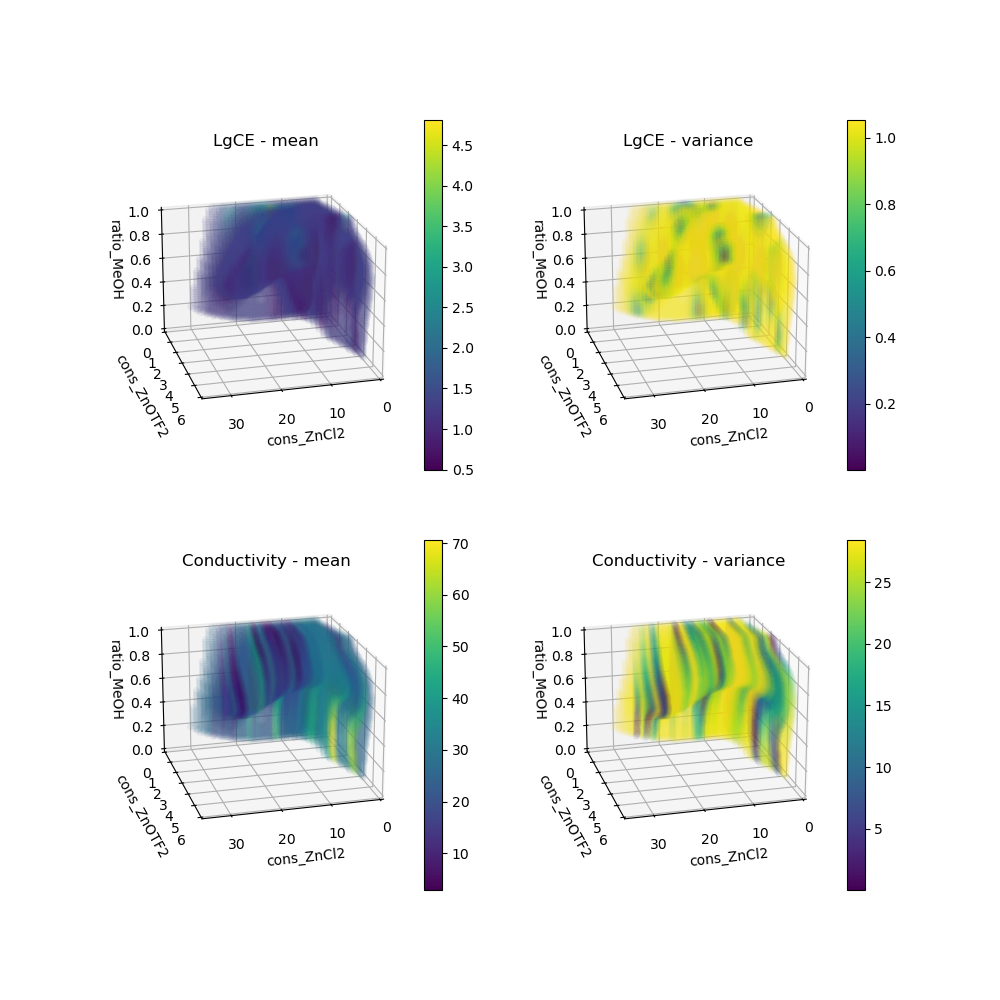

In [6]:
lce_preds = model_lce(to_torch(low_res_X))
con_preds = model_con(to_torch(low_res_X))


plt.close('all')
fig, axs = plt.subplots(2, 2, subplot_kw=dict(projection='3d'), figsize=(10, 10))

for axr, slice_i, ylabel, scaler, preds in [
    (axs[0], 0, 'LgCE',         lce_scaler, lce_preds),
    (axs[1], 1, 'Conductivity', con_scaler, con_preds),
]:
    for ax, val_type in [(axr[0], 'mean'), (axr[1], 'variance'), ]:
        vals = getattr(preds, val_type).detach().numpy()
        if val_type == 'mean':
            vals = scaler.inverse_transform(vals.reshape(-1, 1)).reshape(-1)
        elif val_type == 'variance':
            vals = vals * scaler.scale_[0]
        sc = ax.scatter(*(low_res_X * X_LIMS).T, c=vals, alpha=0.05)
        cbar = plt.colorbar(sc, ax=ax)
        cbar.solids.set(alpha=1)
        
        [getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
        [getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
        ax.view_init(20, 75)

        ax.set_title(f'{ylabel} - {val_type}')

## 2. Define acquisition functions constrained by conductivity

In [7]:
dtype = torch.double

from botorch.acquisition.analytic import ExpectedImprovement, ProbabilityOfImprovement


aqcfs = {}

for bound_tag, lo, hi in [('04', 4, 6), ('06', 6, 8), ('08', 8, 10), 
                          ('10', 10, 15), ('15', 15, 20), ('20', 20, 30), ('30', 30, 50), ]:
    for aqcf_name, aqcf_cls in [('EI', ExpectedImprovement), ('PI', ProbabilityOfImprovement)]:
        sub_df = data_df[(lo <= data_df.Conductivity_Mean) & (data_df.Conductivity_Mean < hi)]
        best_f = sub_df.Scaled_LgCE_Mean.max()
        aqcf = aqcf_cls(model=model_lce, best_f=best_f)
        tag = f'{aqcf_name}_{bound_tag}'
        aqcfs[tag] = [aqcf, lo, hi, best_f]

for bound_tag, lo, hi in [('m5', 0.5, 0.6), ('m6', 0.6, 0.7), ('m7', 0.7, 0.8), ('m8', 0.8, 0.9)]:
    for aqcf_name, aqcf_cls in [('EI', ExpectedImprovement), ('PI', ProbabilityOfImprovement)]:
        sub_df = data_df[(lo <= data_df['ratio_MeOH(wt%)']) & (data_df['ratio_MeOH(wt%)'] < hi)]
        best_f = sub_df.Scaled_LgCE_Mean.max()
        aqcf = aqcf_cls(model=model_lce, best_f=best_f)
        tag = f'{aqcf_name}_{bound_tag}'
        aqcfs[tag] = [aqcf, lo, hi, best_f]
        
aqcfs

{'EI_04': [ExpectedImprovement(
    (model): SingleTaskGP(
      (likelihood): FixedNoiseGaussianLikelihood(
        (noise_covar): FixedGaussianNoise()
      )
      (mean_module): ConstantMean()
      (covar_module): ScaleKernel(
        (base_kernel): MaternKernel(
          (lengthscale_prior): GammaPrior()
          (raw_lengthscale_constraint): Positive()
        )
        (outputscale_prior): GammaPrior()
        (raw_outputscale_constraint): Positive()
      )
    )
  ),
  4,
  6,
  1.0428722145218374],
 'PI_04': [ProbabilityOfImprovement(
    (model): SingleTaskGP(
      (likelihood): FixedNoiseGaussianLikelihood(
        (noise_covar): FixedGaussianNoise()
      )
      (mean_module): ConstantMean()
      (covar_module): ScaleKernel(
        (base_kernel): MaternKernel(
          (lengthscale_prior): GammaPrior()
          (raw_lengthscale_constraint): Positive()
        )
        (outputscale_prior): GammaPrior()
        (raw_outputscale_constraint): Positive()
      )
    )

In [8]:
import copy
from scipy.spatial.distance import pdist, cdist, squareform
from tqdm.auto import tqdm


def pred_conductivity(comp):
    X = to_torch(np.array([comp / X_LIMS])).to(dtype)
    conductivity = model_con(X).mean.detach().numpy()
    conductivity = con_scaler.inverse_transform(conductivity.reshape(-1, 1)).reshape(-1)
    return conductivity[0]

def pred_lce(comp):
    X = to_torch(np.array([comp / X_LIMS])).to(dtype)
    lce = model_lce(X).mean.detach().numpy()
    lce = lce_scaler.inverse_transform(lce.reshape(-1, 1)).reshape(-1)
    return lce[0]

_LIMS = np.array([35.0, 6.0, 1.0])


@ignore_warnings(category=UserWarning)
def _pred_feasibility(comp, svm_models=None, scale=X_LIMS, kdtree=None, 
                     min_dist=0, min_comp=0, her_cutoff=-0.86, oer_cutoff=1.74, 
                     max_comp=1.0):
    comp = np.array(comp) / scale
    
    if svm_models is not None:
        sol = svm_models['solubility'].predict([comp])[0]
        her = svm_models['HER'].predict([comp])[0]
        oer = svm_models['OER'].predict([comp])[0]
        result = sol & (her >= her_cutoff) & (oer >= oer_cutoff)
    else:
        result = True

    if (kdtree is not None) and (min_dist > 0.0):
        dist, min_idx = kdtree.query([comp])
        result = result & (dist[0] > min_dist)

    if min_comp > 0.0:
        result = result & (min(comp) >= min_comp)

    if max_comp < 1.0:
        result = result & (max(comp) <= max_comp)

    return 1.0 if result else 0.0


from functools import partial


pred_feasibility = partial(_pred_feasibility,
                           kdtree=kdtree, 
                           min_dist=0.01, 
                           min_comp=0.05, 
                           max_comp=0.99, 
                           svm_models=svm_models)

def botorch_aqcf_wrapper(aqcf):
    def fun(x):
        return -aqcf(to_torch(np.array([x]) / X_LIMS)).detach().cpu().numpy()[0]
    return fun


from scipy.optimize import NonlinearConstraint, LinearConstraint, differential_evolution
import warnings



opt_results = {}
opt_rows = []
for tag, (aqcf, lo, hi, best_f) in tqdm(aqcfs.items()):
    py_aqcf = botorch_aqcf_wrapper(aqcf)
    
    nc_feas = NonlinearConstraint(pred_feasibility, 0.9, 2.0)
    
    nc_cond = NonlinearConstraint(pred_conductivity, lo, hi)
    lc_meoh = LinearConstraint(np.array([[0., 0., 1.]]), lb=lo, ub=hi)
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        opt = differential_evolution(
            py_aqcf, 
            bounds=[(0, 35.0), (0, 6.0), (0, 1.0)], 
            constraints=[nc_feas, lc_meoh if '_m' in tag else nc_cond],
            seed=0,
            polish=False
            )
    opt_results[tag] = opt
    opt_rows.append(dict(Tag=tag, cons_ZnCl2=opt.x[0], cons_ZnOTF2=opt.x[1], ratio_MeOH=opt.x[2],
                   Aqcf_Val=-opt.fun, LCE=pred_lce(opt.x), Conductivity=pred_conductivity(opt.x),
                   Feasible=pred_feasibility(opt.x)))
    
pd.DataFrame(opt_rows).round(5)

  0%|          | 0/22 [00:00<?, ?it/s]

,Tag,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,Aqcf_Val,LCE,Conductivity,Feasible
0,EI_04,13.43821,0.50999,0.98938,2.78449,5.29776,4.19311,1.0
1,PI_04,13.44362,0.50496,0.98997,1.00000,5.28020,4.49284,1.0
2,EI_06,10.95997,2.40905,0.84804,0.49096,1.99252,6.49593,1.0
3,PI_06,10.96941,2.32778,0.84298,1.00000,2.11431,6.24156,1.0
4,EI_08,10.64532,2.41363,0.84250,0.30374,1.95567,8.01575,1.0
5,PI_08,11.20510,2.33133,0.84100,0.74804,2.11339,8.01501,1.0
6,EI_10,13.51775,0.51058,0.98974,3.91021,5.28735,10.07890,1.0
7,PI_10,13.55649,0.51293,0.95263,1.00000,4.90547,13.28787,1.0
8,EI_15,13.58088,0.51093,0.98995,4.53370,5.26160,15.05809,1.0
9,PI_15,13.94053,0.51143,0.98463,1.00000,4.85767,18.32197,1.0


In [9]:
opt_df = pd.DataFrame(opt_rows).round(5)
opt_df = opt_df[(opt_df.LCE >= 2.0) & (opt_df.ratio_MeOH <= 0.95) ].reset_index(drop=True)
opt_df

,Tag,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,Aqcf_Val,LCE,Conductivity,Feasible
0,PI_06,10.96941,2.32778,0.84298,1.00000,2.11431,6.24156,1.0
1,PI_08,11.20510,2.33133,0.84100,0.74804,2.11339,8.01501,1.0
2,EI_m5,19.84948,1.50460,0.59708,0.71580,2.37823,7.82305,1.0
3,EI_m6,19.84535,1.50180,0.60133,0.84100,2.38377,8.06790,1.0
4,PI_m7,11.03552,2.33136,0.79996,0.87199,2.07194,4.09547,1.0
5,PI_m8,13.37443,0.50805,0.89996,0.99882,3.81786,3.27286,1.0
